In [ ]:
!apt-get update -qq && apt-get install -qq fluidsynth fluid-soundfont-gm
!pip install -q pyfluidsynth pretty_midi scikit-learn pandas
print("Setup complete!")

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Extracting templates from packages: 100%
Selecting previously unselected package libevdev2:amd64.
(Reading database ... 127324 files and directories currently installed.)
Preparing to unpack .../00-libevdev2_1.13.1+dfsg-1build1_amd64.deb ...
Unpacking libevdev2:amd64 (1.13.1+dfsg-1build1) ...
Selecting previously unselected package at-spi2-common.
Preparing to unpack .../01-at-spi2-common_2.52.0-1build1_all.deb ...
Unpacking at-spi2-common (2.52.0-1build1) ...
Selecting previously unselected package libatspi2.0-0t64:amd64.
Preparing to unpack .../02-libatspi2.0-0t64_2.52.0-1build1_amd64.deb ...
Unpacking libatspi2.0-0t64:amd64 (2.52.0-1build1) ...
Selecting previously unselected package libxtst6:amd64.
Preparing to unpack .../03-libxtst6_2%3a1.2.3-1.1ubuntu0.1_amd64.deb ...
Unpacking libxtst6:amd64 (

# Imports

In [ ]:
import os, random, time
import numpy as np
import pandas as pd
import pretty_midi

# Sound Magic idk 🤷‍♂️

In [ ]:
SF2_PATH = "/usr/share/sounds/sf2/FluidR3_GM.sf2"
SR = 16000                     # 16,000 audio samples per second
N_FFT = 8192                   # High frequency resolution to separate low piano keys
SAMPLES_AUDIO = int(0.5 * SR)  # 0.5-second audio window = 8,000 samples

# Create 176 frequency bins spanning MIDI 21 (A0) to MIDI 108 (C8)
freqs = np.fft.rfftfreq(N_FFT, d=1.0 / SR)
midi_centers = np.linspace(21.0, 108.5, 176)
center_freqs = 440.0 * (2.0 ** ((midi_centers - 69.0) / 12.0))

basis = np.zeros((176, len(freqs)), dtype=np.float32)
for i in range(176):
    f_c = center_freqs[i]
    f_low = f_c * (2.0 ** (-0.5 / 12.0))
    f_high = f_c * (2.0 ** (0.5 / 12.0))
    up = (freqs >= f_low) & (freqs <= f_c)
    down = (freqs > f_c) & (freqs <= f_high)
    if f_c > f_low:
        basis[i, up] = (freqs[up] - f_low) / (f_c - f_low)
    if f_high > f_c:
        basis[i, down] = (f_high - freqs[down]) / (f_high - f_c)

np.save("log_freq_basis.npy", basis)
WINDOW = np.hanning(SAMPLES_AUDIO).astype(np.float32)

print("Filterbank saved! Shape:", basis.shape)

Filterbank saved! Shape: (176, 4097)


In [ ]:
def audio_to_features(wave):
    wave = wave[:SAMPLES_AUDIO].astype(np.float32)
    if len(wave) < SAMPLES_AUDIO:
        wave = np.pad(wave, (0, SAMPLES_AUDIO - len(wave)))
    peak = np.max(np.abs(wave))
    if peak > 1e-4:
        wave = wave / peak
    spec = np.abs(np.fft.rfft(wave * WINDOW, n=N_FFT)).astype(np.float32)
    feat = np.log1p(basis @ spec)
    max_f = np.max(feat)
    if max_f > 1e-6:
        feat = feat / max_f
    return feat

# Test & visual for C major

Click play below to hear the synthesized C Major chord (C4 + E4 + G4):


/tmp/ipykernel_2291/2750019710.py:10: DeprecationWarning: The parameter 'sf2_path' is deprecated, please use 'synthesizer' instead.
  test_wave = pm_test.fluidsynth(fs=SR, sf2_path=SF2_PATH)[:SAMPLES_AUDIO]


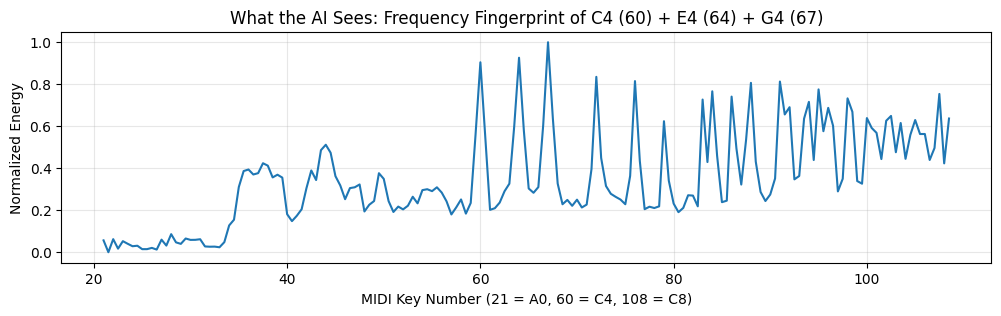

In [ ]:
import matplotlib.pyplot as plt
from IPython.display import Audio, display

pm_test = pretty_midi.PrettyMIDI()
inst_test = pretty_midi.Instrument(program=0)  # Acoustic Grand Piano
for midi_note in [60, 64, 67]:  # C4, E4, G4
    inst_test.notes.append(pretty_midi.Note(velocity=100, pitch=midi_note, start=0.0, end=0.55))
pm_test.instruments.append(inst_test)

test_wave = pm_test.fluidsynth(fs=SR, sf2_path=SF2_PATH)[:SAMPLES_AUDIO]
test_feat = audio_to_features(test_wave)

print("Click play below to hear the synthesized C Major chord (C4 + E4 + G4):")
display(Audio(test_wave, rate=SR))

plt.figure(figsize=(12, 3))
plt.plot(midi_centers, test_feat)
plt.title("What the AI Sees: Frequency Fingerprint of C4 (60) + E4 (64) + G4 (67)")
plt.xlabel("MIDI Key Number (21 = A0, 60 = C4, 108 = C8)")
plt.ylabel("Normalized Energy")
plt.grid(True, alpha=0.3)
plt.show()

# Creating dataset for note detection

In [ ]:
import fluidsynth

NUM_SAMPLES = 25000
X = np.zeros((NUM_SAMPLES, 176), dtype=np.float32)
Y = np.zeros((NUM_SAMPLES, 88), dtype=np.float32)

# 0 = Acoustic Grand (~71%), 1 = Bright Piano (~21%), 4 = Electric Piano (~7%)
PROGRAMS = [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 4]

# Load the 140 MB SoundFont ONCE into RAM and pass it directly to pretty_midi!
fs_synth = fluidsynth.Synth(samplerate=float(SR))
sfid = fs_synth.sfload(SF2_PATH)
fs_synth.program_select(0, sfid, 0, 0)

# --- 200% VERIFICATION CHECK - Old version took 75 minutes. 3.5TB data  ---
pm_chk = pretty_midi.PrettyMIDI()
inst_chk = pretty_midi.Instrument(program=0)
inst_chk.pitch_bends.append(pretty_midi.PitchBend(pitch=750, time=0.0))
inst_chk.control_changes.append(pretty_midi.ControlChange(number=64, value=127, time=0.0))
for m in [60, 64, 67]:
    inst_chk.notes.append(pretty_midi.Note(velocity=100, pitch=m, start=0.05, end=0.30))
pm_chk.instruments.append(inst_chk)

feat_slow = audio_to_features(pm_chk.fluidsynth(fs=SR, sf2_path=SF2_PATH)[:SAMPLES_AUDIO])
feat_fast = audio_to_features(pm_chk.fluidsynth(fs=SR, synthesizer=fs_synth)[:SAMPLES_AUDIO])
corr = np.corrcoef(feat_slow, feat_fast)[0, 1]
max_diff = np.max(np.abs(feat_slow - feat_fast))
print(f"Verification match: {corr * 100:.4f}% | Max bin difference: {max_diff:.6f}")
assert corr > 0.999, "Mismatch detected!"

# --- MAIN LOOP (100% your original code, just passing synthesizer=fs_synth!) ---
print(f"Generating {NUM_SAMPLES} piano clips (with sustain pedal simulation)...")
t0 = time.time()

for idx in range(NUM_SAMPLES):
    r = random.random()
    if r < 0.05:
        wave = np.random.normal(0, random.uniform(0.001, 0.02), SAMPLES_AUDIO)
        X[idx] = audio_to_features(wave)
        continue

    pm = pretty_midi.PrettyMIDI()
    inst = pretty_midi.Instrument(program=random.choice(PROGRAMS))
    inst.pitch_bends.append(pretty_midi.PitchBend(pitch=random.randint(-1500, 1500), time=0.0))

    use_pedal = random.random() < 0.50
    if use_pedal:
        inst.control_changes.append(pretty_midi.ControlChange(number=64, value=127, time=0.0))

    if r < 0.30:
        notes = [random.randint(21, 108)]  # 25% Single key
    elif r < 0.50:
        root = random.randint(24, 96)      # 20% 2-note interval
        notes = [root, root + random.choice([3, 4, 5, 7, 8, 9, 12])]
    elif r < 0.85:
        root = random.randint(36, 84)      # 35% 3-note triad + inversions
        chord_type = random.choice([[0, 4, 7], [0, 3, 7], [0, 3, 6], [0, 5, 7], [-5, 0, 4], [-4, 0, 3]])
        notes = [n for n in [root + iv for iv in chord_type] if 21 <= n <= 108]
    else:
        root = random.randint(36, 80)      # 15% 4-note 7th chord
        chord_type = random.choice([[0, 4, 7, 11], [0, 4, 7, 10], [0, 3, 7, 10]])
        notes = [n for n in [root + iv for iv in chord_type] if 21 <= n <= 108]

    for m in notes:
        start_t = random.uniform(0.0, 0.22) if (use_pedal and len(notes) > 1) else random.uniform(0.0, 0.04)
        end_t = random.uniform(start_t + 0.12, 0.55) if use_pedal else 0.55
        vel = random.randint(50, 120)
        inst.notes.append(pretty_midi.Note(velocity=vel, pitch=m, start=start_t, end=end_t))
        Y[idx, m - 21] = 1.0

    pm.instruments.append(inst)
    # Reset pitch bend & sustain between clips, then call pretty_midi's official synthesizer param!
    fs_synth.cc(0, 64, 0)
    fs_synth.pitch_bend(0, 8192)
    wave = pm.fluidsynth(fs=SR, synthesizer=fs_synth)[:SAMPLES_AUDIO]
    wave = wave + np.random.normal(0, random.uniform(0.002, 0.015), len(wave))
    X[idx] = audio_to_features(wave)

    if (idx + 1) % 5000 == 0:
        print(f"  {idx + 1}/{NUM_SAMPLES} generated ({time.time() - t0:.1f}s)")

fs_synth.delete()
print("Dataset ready! X shape:", X.shape, "| Y shape:", Y.shape)

/tmp/ipykernel_2291/285886511.py:24: DeprecationWarning: The parameter 'sf2_path' is deprecated, please use 'synthesizer' instead.
  feat_slow = audio_to_features(pm_chk.fluidsynth(fs=SR, sf2_path=SF2_PATH)[:SAMPLES_AUDIO])


Verification match: 100.0000% | Max bin difference: 0.000000
Generating 25000 piano clips (with sustain pedal simulation)...
  5000/25000 generated (43.9s)
  10000/25000 generated (84.4s)
  15000/25000 generated (125.6s)
  20000/25000 generated (166.5s)
  25000/25000 generated (207.6s)
Dataset ready! X shape: (25000, 176) | Y shape: (25000, 88)


# Train Keras model

In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split

X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=42)

model = keras.Sequential([
    layers.Input(shape=(176,)),
    layers.Dense(320, activation="relu"),
    layers.BatchNormalization(),
    layers.Dropout(0.25),
    layers.Dense(224, activation="relu"),
    layers.BatchNormalization(),
    layers.Dropout(0.20),
    layers.Dense(88, activation="sigmoid"),  # 88 independent piano keys
])

model.compile(optimizer=keras.optimizers.Adam(1e-3), loss="binary_crossentropy")
history = model.fit(X_train, Y_train, validation_data=(X_test, Y_test), epochs=45, batch_size=64, verbose=1)

model.save("piano_88.keras")
print("Saved base Keras model: piano_88.keras")

Epoch 1/45
313/313 ━━━━━━━━━━━━━━━━━━━━ 8s 14ms/step - loss: 0.2670 - val_loss: 0.0751
Epoch 2/45
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0304 - val_loss: 0.0189
Epoch 3/45
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0186 - val_loss: 0.0123
Epoch 4/45
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0140 - val_loss: 0.0088
Epoch 5/45
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0115 - val_loss: 0.0104
Epoch 6/45
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0102 - val_loss: 0.0121
Epoch 7/45
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0091 - val_loss: 0.0079
Epoch 8/45
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0083 - val_loss: 0.0081
Epoch 9/45
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0079 - val_loss: 0.0061
Epoch 10/45
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0074 - val_loss: 0.0074
Epoch 11/45
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.0069 - val_loss: 0.0053
Epoch 12/45
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/ste

# TF TO TFLite

In [ ]:
# 1. Standard TFLite (Float32 - keeps maximum accuracy)
converter = tf.lite.TFLiteConverter.from_keras_model(model)
tflite_fp32 = converter.convert()
open("piano_88.tflite", "wb").write(tflite_fp32)

# 2. Quantized TFLite (Post-Training Quantization - smaller file size)
converter_q = tf.lite.TFLiteConverter.from_keras_model(model)
converter_q.optimizations = [tf.lite.Optimize.DEFAULT]
tflite_quant = converter_q.convert()
open("piano_88_quant.tflite", "wb").write(tflite_quant)

print("Converted both TFLite models successfully!")

Saved artifact at '/tmp/tmpjazrx7l4'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 176), dtype=tf.float32, name='keras_tensor_8')
Output Type:
  TensorSpec(shape=(None, 88), dtype=tf.float32, name=None)
Captures:
  138959843108496: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138959843113488: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138959843104656: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138959843104848: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138959843109840: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138959843104272: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138959843113680: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138959843114640: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138959843114256: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138959843114064: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138959843108112: Te

# Benchmark

In [ ]:
from sklearn.metrics import f1_score, accuracy_score

def eval_tflite(path, X_data):
    interp = tf.lite.Interpreter(model_path=path)
    interp.allocate_tensors()
    in_idx = interp.get_input_details()[0]["index"]
    out_idx = interp.get_output_details()[0]["index"]
    preds = np.zeros((len(X_data), 88), dtype=np.float32)

    t_start = time.perf_counter()
    for i in range(len(X_data)):
        interp.set_tensor(in_idx, X_data[i:i+1])
        interp.invoke()
        preds[i] = interp.get_tensor(out_idx)[0]
    ms_per_sample = ((time.perf_counter() - t_start) / len(X_data)) * 1000.0
    return preds, ms_per_sample

t_k = time.perf_counter()
preds_keras = model.predict(X_test, batch_size=1, verbose=0)
ms_keras = ((time.perf_counter() - t_k) / len(X_test)) * 1000.0

preds_fp32, ms_fp32 = eval_tflite("piano_88.tflite", X_test)
preds_quant, ms_quant = eval_tflite("piano_88_quant.tflite", X_test)

results = []
for name, fname, p, lat in [
    ("Base Keras (.keras)", "piano_88.keras", preds_keras, ms_keras),
    ("Standard TFLite (FP32)", "piano_88.tflite", preds_fp32, ms_fp32),
    ("Quantized TFLite (INT8)", "piano_88_quant.tflite", preds_quant, ms_quant),
]:
    bin_p = (p >= 0.5).astype(int)
    f1 = f1_score(Y_test, bin_p, average="micro") * 100
    exact = accuracy_score(Y_test, bin_p) * 100
    size_kb = os.path.getsize(fname) / 1024.0
    results.append({
        "Model": name,
        "Size (KB)": round(size_kb, 1),
        "Note F1 (%)": round(f1, 2),
        "Exact Chord Match (%)": round(exact, 2),
        "Latency (ms)": round(lat, 3),
    })

print("\n=== EDGE AI OPTIMIZATION BENCHMARK ===")
print(pd.DataFrame(results).to_string(index=False))

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)



=== EDGE AI OPTIMIZATION BENCHMARK ===
                  Model  Size (KB)  Note F1 (%)  Exact Chord Match (%)  Latency (ms)
    Base Keras (.keras)     1796.1        97.48                  89.76         1.839
 Standard TFLite (FP32)      582.2        97.48                  89.76         0.021
Quantized TFLite (INT8)      157.0        97.40                  89.44         0.017


# Dataset for Azure AutoML (detecting the key)

In [ ]:
NOTE_NAMES = ["C", "Cs", "D", "Ds", "E", "F", "Fs", "G", "Gs", "A", "As", "B"]
CAMELOT_KEYS = [
    ("8B - C Major", 0, "major"), ("3B - Db Major", 1, "major"), ("10B - D Major", 2, "major"),
    ("5B - Eb Major", 3, "major"), ("12B - E Major", 4, "major"), ("7B - F Major", 5, "major"),
    ("2B - F# Major", 6, "major"), ("9B - G Major", 7, "major"), ("4B - Ab Major", 8, "major"),
    ("11B - A Major", 9, "major"), ("6B - Bb Major", 10, "major"), ("1B - B Major", 11, "major"),
    ("5A - C Minor", 0, "minor"), ("12A - C# Minor", 1, "minor"), ("7A - D Minor", 2, "minor"),
    ("2A - Eb Minor", 3, "minor"), ("9A - E Minor", 4, "minor"), ("4A - F Minor", 5, "minor"),
    ("11A - F# Minor", 6, "minor"), ("6A - G Minor", 7, "minor"), ("1A - Ab Minor", 8, "minor"),
    ("8A - A Minor", 9, "minor"), ("3A - Bb Minor", 10, "minor"), ("10A - B Minor", 11, "minor"),
]
MAJOR_INTERVALS = [0, 2, 4, 5, 7, 9, 11]
MINOR_INTERVALS = [0, 2, 3, 5, 7, 8, 10]

rows = []
for label, root, mode in CAMELOT_KEYS:
    intervals = MAJOR_INTERVALS if mode == "major" else MINOR_INTERVALS
    scale_pcs = [(root + iv) % 12 for iv in intervals]
    weights = [3.0, 1.0, 2.2, 1.3, 2.5, 1.2, 1.2]
    for _ in range(500):  # 500 x 24 = 12,000 rows
        n_notes = random.randint(6, 35)
        played = random.choices(scale_pcs, weights=weights, k=n_notes)
        played = [((p + random.choice([-1, 1])) % 12 if random.random() < 0.05 else p) for p in played]
        counts = np.bincount(played, minlength=12) / float(n_notes)
        first_pc = root if random.random() < 0.6 else scale_pcs[random.choice([0, 2, 4])]
        last_pc = root if random.random() < 0.75 else scale_pcs[4]
        rows.append(list(np.round(counts, 4)) + [first_pc, last_pc, label])

cols = [f"pct_{n}" for n in NOTE_NAMES] + ["first_pc", "last_pc", "musical_key"]
pd.DataFrame(rows, columns=cols).to_csv("camelot_keys.csv", index=False)
print("Saved camelot_keys.csv (12,000 rows)!")

from google.colab import files
for f in ["piano_88.tflite", "piano_88_quant.tflite", "log_freq_basis.npy", "camelot_keys.csv"]:
    files.download(f)

Saved camelot_keys.csv (12,000 rows)!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>